# 23. Одна гауссиана между тремя снимками

[План курса](../../README_ru.md)

На первом снимке рыжее пятно слева, на втором — справа. Если соединить два центра прямой, получится аккуратная анимация. Третий снимок, сделанный посередине, сразу показывает промах. У пятна меняется ещё и силуэт. Разберём отдельно движение центра и изменение формы.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dynamic_motion.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import dynamic_motion as motion
from dynamic_motion_demos import motion_figure, motion_lab
lang = 'ru'

## Две отметки уже задают прямую

Камера та же, что в предыдущем опыте. Глубина 4 м известна, середина кадра $u_0=48$ px, фокус $f=80$ px. В моменты 0 и 2 секунды центр попал в столбцы 38 и 62. У первого снимка смещение $38-48=-10$ px. Деление на 80 даёт наклон $-0.125$, умножение на 4 м — положение $-0.5$ м. У второго $(62-48)\cdot4/80=0.7$ м. Так из двух наблюдений получились две пространственные отметки.

За 2 с пятно прошло от $-0.5$ до $0.7$ м. Разность $0.7-(-0.5)=1.2$ м, средняя скорость $1.2/2=0.6$ м/с. Если принять эту скорость постоянной, через секунду центр будет при $-0.5+0.6=0.1$ м. На графике пунктир соединяет известные отметки. Зелёная кривая показывает скрытое при подгонке движение стенда. Справа вертикальный штрих отмечает его проекцию.

In [2]:
display(motion_lab(23, lang))

In [3]:
pixels = np.array([38., 62.])
positions = (pixels - motion.U0) * motion.DEPTH / motion.F
v = (positions[1] - positions[0]) / 2
print('x (m)', positions, '  v (m/s)', v, '  x(1) (m)', round(positions[0] + v, 3))

x (m) [-0.5  0.7]   v (m/s) 0.6   x(1) (m) 0.1


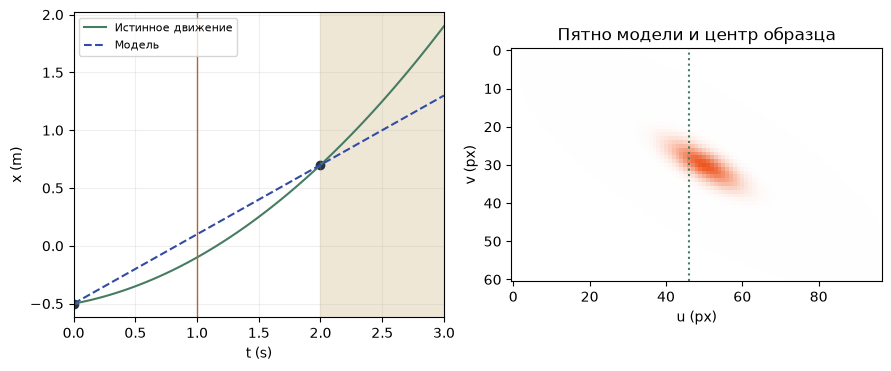

In [4]:
fig = motion_figure(23, lang)
plt.show()

## Ещё один кадр меняет изгиб

В центре интервала камера на самом деле видит столбец 46. Положение $(46-48)\cdot4/80=-0.1$ м. Прямая промахнулась на $0.2$ м, или $80\cdot0.2/4=4$ пикселя. Откуда взять изгиб, который не сдвинет оба уже измеренных конца?

Обозначим время числами секунд. Пусть $h=t/(1\,\mathrm{s})$ — число без единиц. Произведение $g=h(2-h)$ равно нулю при $h=0$ и при $h=2$. При $h=1$ оно равно единице. Значит, если умножить $g$ на отклонение среднего снимка от прямой, поправка будет действовать именно там, где нужна. Обозначим прямую через $l(t)$, а измеренный центр через $x_1$ в метрах.

$$
\begin{aligned}
l(t)&=-0.5+0.6h\quad\text{(m)},\\
x_1-l(1\,\mathrm{s})&=-0.1-0.1=-0.2\quad\text{(m)},\\
x_{\mathrm{fit}}(t)&=l(t)+(x_1-l(1\,\mathrm{s}))\,h(2-h).
\end{aligned}
$$

При половине секунды прямая даёт $-0.5+0.3=-0.2$ м. Вес поправки $0.5(2-0.5)=0.75$. Итого $-0.2-0.2\cdot0.75=-0.35$ м, то есть столбец 41. Две модели проверяются на промежуточном кадре, которого ни одна из них не использовала при подгонке.

In [5]:
for t in [0, .5, 1, 2, 3]:
    truth = motion.true_x(t)
    for third in [False, True]:
        fitted = motion.fit_path(t, middle=third)
        print(f"t={t:.1f} s   n={2+int(third)}   x={fitted:+.3f} m   |Δu|={20*abs(fitted-truth):.2f} px")

t=0.0 s   n=2   x=-0.500 m   |Δu|=0.00 px
t=0.0 s   n=3   x=-0.500 m   |Δu|=0.00 px
t=0.5 s   n=2   x=-0.200 m   |Δu|=3.00 px
t=0.5 s   n=3   x=-0.350 m   |Δu|=0.00 px
t=1.0 s   n=2   x=+0.100 m   |Δu|=4.00 px
t=1.0 s   n=3   x=-0.100 m   |Δu|=0.00 px
t=2.0 s   n=2   x=+0.700 m   |Δu|=0.00 px
t=2.0 s   n=3   x=+0.700 m   |Δu|=0.00 px
t=3.0 s   n=2   x=+1.300 m   |Δu|=12.00 px
t=3.0 s   n=3   x=+1.900 m   |Δu|=0.00 px


## Что поворачивается у самого пятна

Пятно живёт при $z=4$ м и $y=0$. Длинный масштаб растёт с 0.24 м на 0.08 м за каждую секунду. Через секунду $s_x=0.24+0.08=0.32$ м. Поперечный масштаб остаётся 0.11 м, в глубину — 0.08 м. Все три положительны на всём показанном интервале от 0 до 3 с. За секунду длинная ось поворачивается на $30^\circ$ вокруг оси глубины. Камера смотрит вдоль этой оси, экранная вертикаль направлена вниз, так что поворот виден по часовой стрелке.

Рендерер из урока 14 принимает четыре числа поворота. Для оси $(0,0,1)$ угол делится пополам. При $30^\circ$ половина составляет $15^\circ$, первая компонента равна $\cos(15^\circ)\approx0.966$, последняя равна $\sin(15^\circ)\approx0.259$, две остальные нулевые. Изменения масштаба и ориентации в опыте заданы заранее. По измеренным столбцам восстанавливается только траектория центра.

In [6]:
spot = motion.trajectory_splat(1, motion.fit_path(1, middle=True))
for key in ['center', 'scales', 'rotation']:
    print(key, np.round(spot[key], 4))

center [-0.1  0.   4. ]
scales [0.32 0.11 0.08]
rotation [0.9659 0.     0.     0.2588]


## За последним замером

Слева от отметки 2 с, между наблюдениями, идёт интерполяция. Справа начинается экстраполяция. В искусственной сцене истинная траектория устроена как прямая плюс $a\,t(t-2\,\mathrm{s})$. Здесь $a$ измеряется в м/с². При $a=0.2$ три точных замера полностью задают эту параболу. Реальное пятно после последнего кадра может остановиться даже при безупречной подгонке всех трёх точек.

Если средний замер сбит на $+0.1$ м, ошибка умножается на $h(2-h)$. Через 0.5 с получается $+0.075$ м. Через 3 с получится $0.1\cdot3\cdot(-1)=-0.3$ м. Сдвиг средней отметки вправо увёл предсказание влево и утроил ошибку. На следующем рисунке виден зазор между пятном и зелёным штрихом.

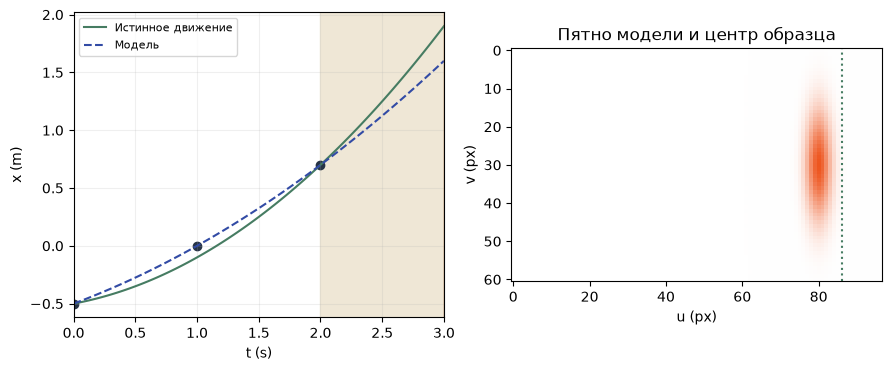

In [7]:
fig = motion_figure(23, lang, time=3, middle=True, noise=.1)
plt.show()

**Что останется на экране, если взять другие числа?** Движение прямолинейное, средний замер сбит на $+0.1$ м. Какой из двух способов подгонки точнее в момент 3 с?

<details><summary>Разбор</summary>

Прямая по двум точным концам продолжит реальный путь. Парабола пройдёт через все три измерения и промахнётся на 0.3 м влево. При масштабе 20 пикселей на метр это 6 пикселей. Больше измерений помогает, если вместе с ними учитывается и точность. Здесь подгонка обязана пройти даже через испорченную точку.

</details>